# Anomaly Classifier for AeroNet Lite

In [ ]:
# Anomaly Classifier for AeroNet Lite - Module 5
# This notebook demonstrates synthetic telemetry generation and anomaly detection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


ANOMALY DETECTION FOR DRONE DELIVERY SYSTEM


In [ ]:
# ============================================
# PART 1: GENERATE SYNTHETIC TELEMETRY DATA
# ============================================

def create_synthetic_telemetry(n_samples=1000, random_seed=42):
    """
    Generate synthetic telemetry with classes:
    - normal (85%): normal operations
    - battery_anomaly (5%): sudden battery drop
    - route_anomaly (5%): large route deviation
    - sensor_spike (5%): sudden speed/altitude jump
    
    Features:
    - battery_drop (% per minute)
    - speed (m/s)
    - route_deviation (meters off planned path)
    """
    rng = np.random.RandomState(random_seed)
    
    # Define classes and probabilities
    classes = ["normal", "battery_anomaly", "route_anomaly", "sensor_spike"]
    probs = [0.85, 0.05, 0.05, 0.05]
    
    # Generate labels
    labels = rng.choice(classes, size=n_samples, p=probs)
    
    # Initialize feature arrays
    battery_drop = np.zeros(n_samples)
    speed = np.zeros(n_samples)
    route_deviation = np.zeros(n_samples)
    
    for i, label in enumerate(labels):
        if label == "normal":
            battery_drop[i] = rng.uniform(0, 5)  # 0-5% drop
            speed[i] = rng.normal(10, 2)  # 10 m/s avg
            route_deviation[i] = rng.uniform(0, 10)  # 0-10m off path
            
        elif label == "battery_anomaly":
            battery_drop[i] = rng.uniform(20, 60)  # Sudden 20-60% drop!
            speed[i] = rng.normal(10, 2)
            route_deviation[i] = rng.uniform(0, 10)
            
        elif label == "route_anomaly":
            battery_drop[i] = rng.uniform(0, 5)
            speed[i] = rng.normal(10, 2)
            route_deviation[i] = rng.uniform(50, 200)  # Way off path!
            
        elif label == "sensor_spike":
            battery_drop[i] = rng.uniform(0, 5)
            speed[i] = rng.normal(60, 20)  # Sudden speed spike!
            route_deviation[i] = rng.uniform(0, 10)
    
    # Create DataFrame
    df = pd.DataFrame({
        'battery_drop': battery_drop,
        'speed': speed,
        'route_deviation': route_deviation,
        'anomaly_label': labels
    })
    
    return df

# Generate the synthetic data
print("\n GENERATING SYNTHETIC TELEMETRY DATA\n\n")

df = create_synthetic_telemetry(n_samples=1000, random_seed=RANDOM_SEED)

print(f"Total samples: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
print("\nFirst 5 rows:")
print(df.head())


📊 GENERATING SYNTHETIC TELEMETRY DATA
----------------------------------------
Total samples: 1000
Columns: ['battery_drop', 'speed', 'route_deviation', 'anomaly_label']

First 5 rows:
   battery_drop      speed  route_deviation anomaly_label
0      0.925665  12.129137         7.322249        normal
1      4.032806  62.392113         6.587834  sensor_spike
2      3.461383   9.092511         4.894250        normal
3      1.106047  11.265883         9.876680        normal
4      4.720297  11.636969         0.339460        normal


In [ ]:
# ============================================
# PART 2: EXPLORE THE DATA
# ============================================

print("\n DATA EXPLORATION")

# Class distribution
print("\nClass Distribution:")
class_counts = df['anomaly_label'].value_counts()
print(class_counts)
print(f"\nPercentages:")
print(df['anomaly_label'].value_counts(normalize=True) * 100)

# Statistical summary by class
print("\nStatistical Summary by Class:")
print(df.groupby('anomaly_label').describe())


📈 DATA EXPLORATION
----------------------------------------

Class Distribution:
anomaly_label
normal             847
route_anomaly       54
battery_anomaly     53
sensor_spike        46
Name: count, dtype: int64

Percentages:
anomaly_label
normal             84.7
route_anomaly       5.4
battery_anomaly     5.3
sensor_spike        4.6
Name: proportion, dtype: float64

Statistical Summary by Class:
                battery_drop                                              \
                       count       mean        std        min        25%   
anomaly_label                                                              
battery_anomaly         53.0  38.569468  12.151201  20.000465  29.889243   
normal                 847.0   2.543824   1.463507   0.003267   1.265326   
route_anomaly           54.0   2.537090   1.438519   0.021816   1.269485   
sensor_spike            46.0   2.232768   1.557651   0.049619   0.831681   

                                                  speed          


📊 GENERATING VISUALIZATIONS
----------------------------------------


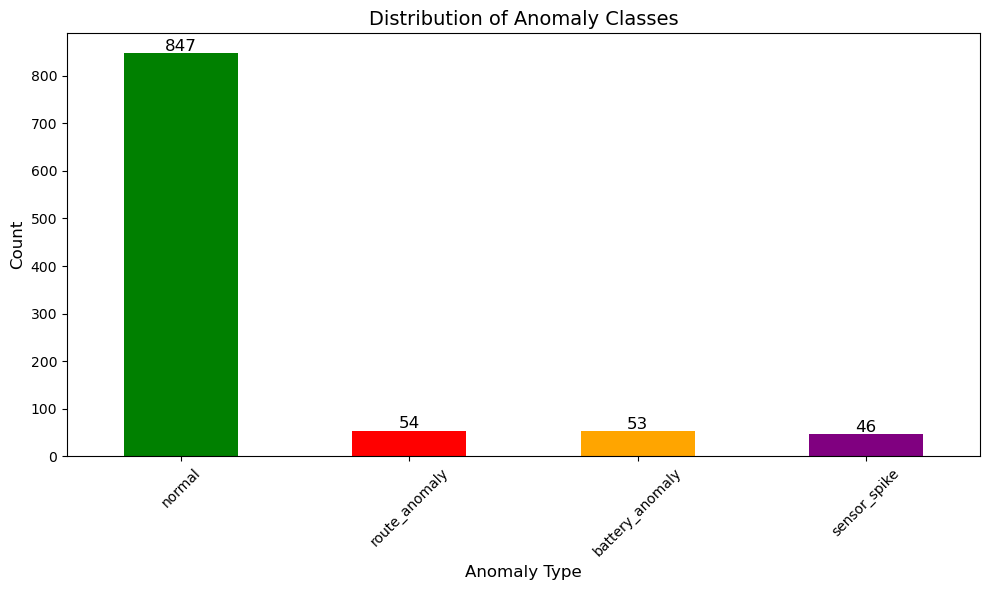

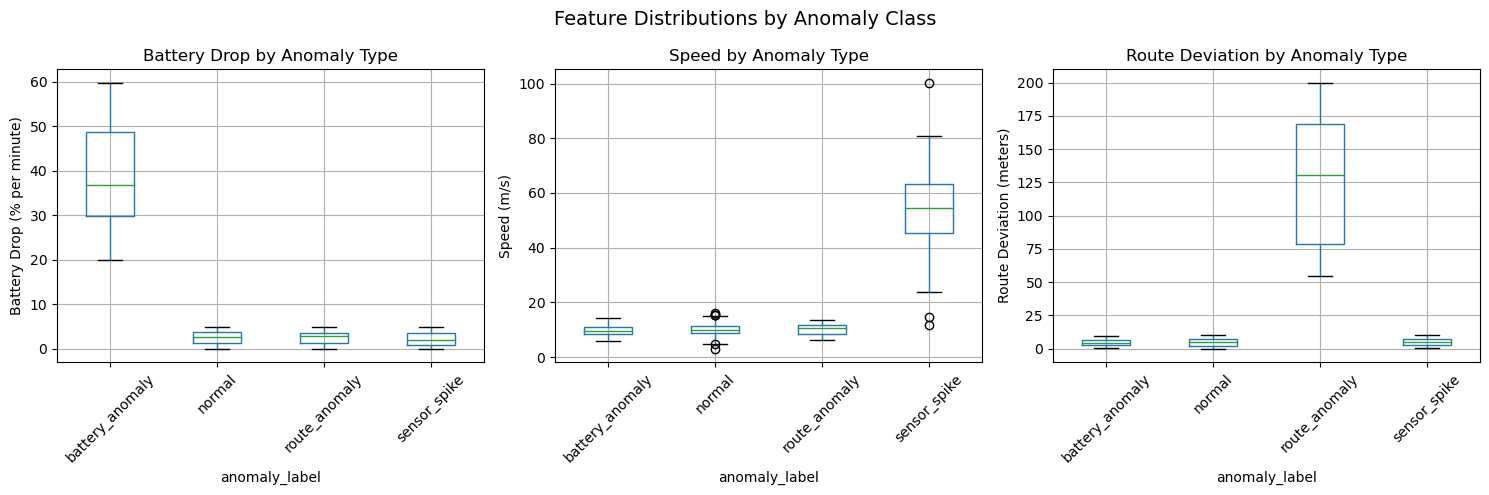

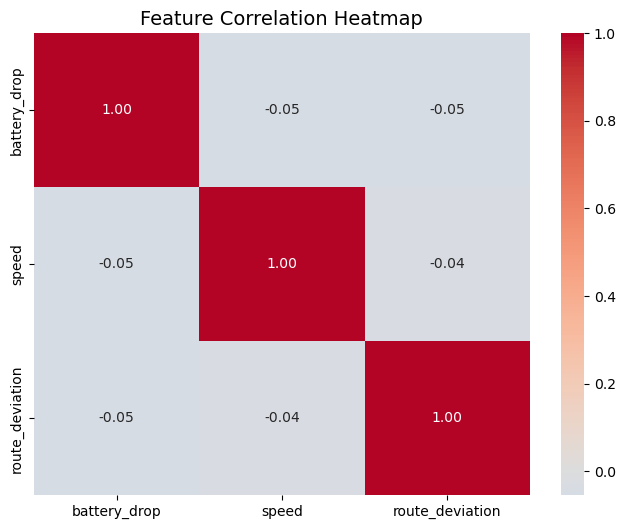

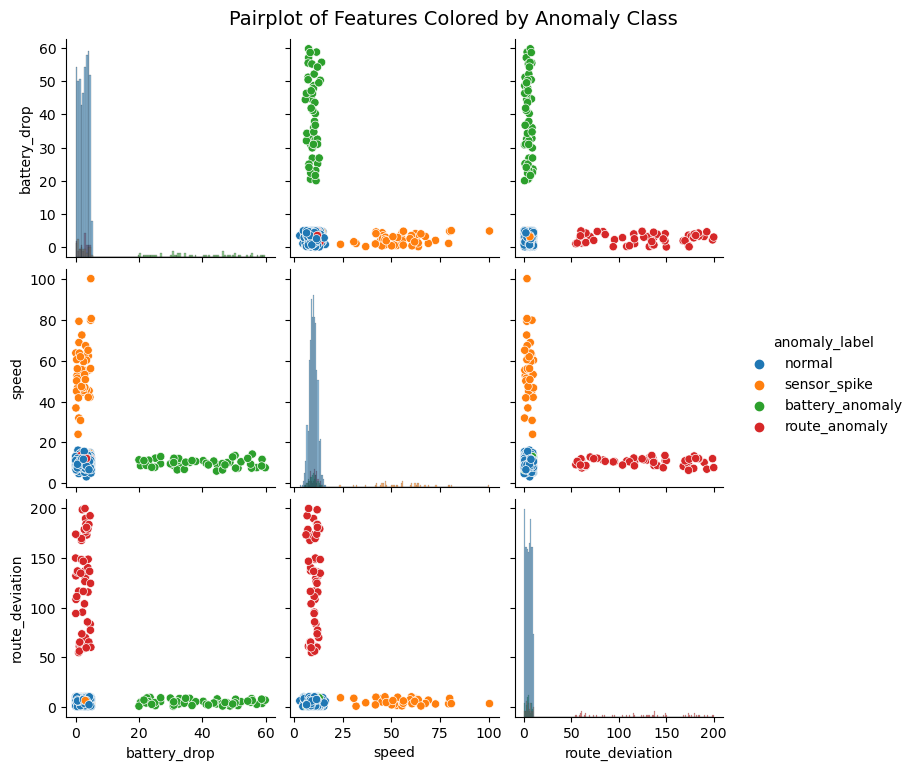

In [ ]:
# ============================================
# PART 3: VISUALIZATIONS
# ============================================

print("\nGENERATING VISUALIZATIONS")


# Figure 1: Class Distribution Bar Plot
plt.figure(figsize=(10, 6))
colors = ['green', 'red', 'orange', 'purple']
class_counts.plot(kind='bar', color=colors)
plt.title('Distribution of Anomaly Classes', fontsize=14)
plt.xlabel('Anomaly Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
for i, v in enumerate(class_counts.values):
    plt.text(i, v + 5, str(v), ha='center', fontsize=12)
plt.tight_layout()
plt.show()

# Figure 2: Box plots for each feature by class
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Battery drop by class
df.boxplot(column='battery_drop', by='anomaly_label', ax=axes[0])
axes[0].set_title('Battery Drop by Anomaly Type')
axes[0].set_ylabel('Battery Drop (% per minute)')
axes[0].tick_params(axis='x', rotation=45)

# Speed by class
df.boxplot(column='speed', by='anomaly_label', ax=axes[1])
axes[1].set_title('Speed by Anomaly Type')
axes[1].set_ylabel('Speed (m/s)')
axes[1].tick_params(axis='x', rotation=45)

# Route deviation by class
df.boxplot(column='route_deviation', by='anomaly_label', ax=axes[2])
axes[2].set_title('Route Deviation by Anomaly Type')
axes[2].set_ylabel('Route Deviation (meters)')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Feature Distributions by Anomaly Class', fontsize=14)
plt.tight_layout()
plt.show()

# Figure 3: Correlation Heatmap
plt.figure(figsize=(8, 6))
correlation = df[['battery_drop', 'speed', 'route_deviation']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Heatmap', fontsize=14)
plt.show()

# Figure 4: Pairplot (scatter matrix)
sns.pairplot(df, hue='anomaly_label', vars=['battery_drop', 'speed', 'route_deviation'], diag_kind='hist')
plt.suptitle('Pairplot of Features Colored by Anomaly Class', y=1.02, fontsize=14)
plt.show()

In [ ]:
# ============================================
# PART 4: PREPARE DATA FOR MODELING
# ============================================

print("\n PREPARING DATA FOR MODEL TRAINING")


# Features and target
feature_cols = ['battery_drop', 'speed', 'route_deviation']
X = df[feature_cols]
y = df['anomaly_label']

# Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"Features: {feature_cols}")
print(f"Target classes: {le.classes_}")
print(f"Encoded mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=RANDOM_SEED, stratify=y_encoded
)

print(f"\nTraining samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Training class distribution: {np.bincount(y_train)}")
print(f"Test class distribution: {np.bincount(y_test)}")


🤖 PREPARING DATA FOR MODEL TRAINING
----------------------------------------
Features: ['battery_drop', 'speed', 'route_deviation']
Target classes: ['battery_anomaly' 'normal' 'route_anomaly' 'sensor_spike']
Encoded mapping: {'battery_anomaly': 0, 'normal': 1, 'route_anomaly': 2, 'sensor_spike': 3}

Training samples: 800
Test samples: 200
Training class distribution: [ 42 678  43  37]
Test class distribution: [ 11 169  11   9]


In [ ]:
# ============================================
# PART 5: TRAIN RANDOM FOREST CLASSIFIER
# ============================================

print("\nTRAINING RANDOM FOREST CLASSIFIER")


# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED)
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf:.4f} ({accuracy_rf*100:.2f}%)")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

# Cross-validation score
cv_scores = cross_val_score(rf_model, X, y_encoded, cv=5)
print(f"\n5-Fold Cross-Validation Scores: {cv_scores}")
print(f"Mean CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")


🌲 TRAINING RANDOM FOREST CLASSIFIER
----------------------------------------
Random Forest Accuracy: 1.0000 (100.00%)

Classification Report:
                 precision    recall  f1-score   support

battery_anomaly       1.00      1.00      1.00        11
         normal       1.00      1.00      1.00       169
  route_anomaly       1.00      1.00      1.00        11
   sensor_spike       1.00      1.00      1.00         9

       accuracy                           1.00       200
      macro avg       1.00      1.00      1.00       200
   weighted avg       1.00      1.00      1.00       200


5-Fold Cross-Validation Scores: [1.    0.995 1.    0.995 1.   ]
Mean CV Score: 0.9980 (+/- 0.0049)


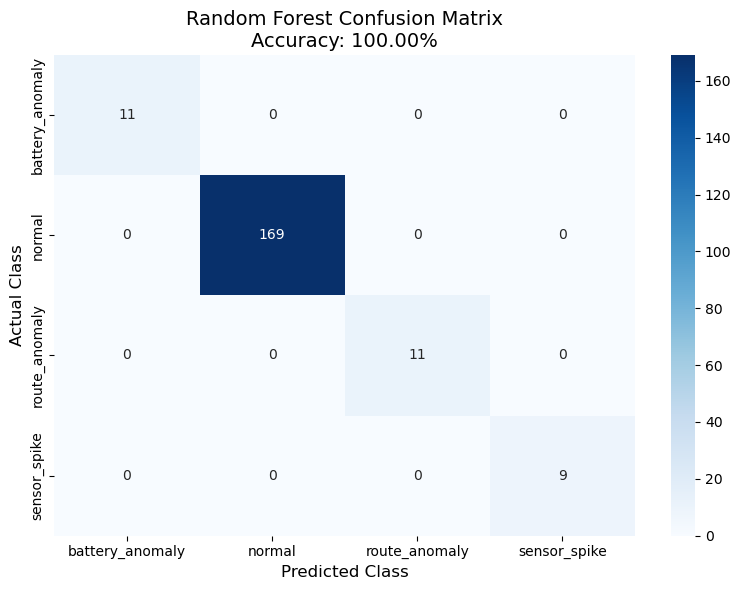


Confusion Matrix (Raw):
[[ 11   0   0   0]
 [  0 169   0   0]
 [  0   0  11   0]
 [  0   0   0   9]]

Interpretation:
- Normal correctly classified: 11 / 11
- Battery anomalies correctly classified: 169 / 169
- Route anomalies correctly classified: 11 / 11
- Sensor spikes correctly classified: 9 / 9


In [7]:
# ============================================
# PART 6: CONFUSION MATRIX VISUALIZATION
# ============================================

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, 
            yticklabels=le.classes_)
plt.title(f'Random Forest Confusion Matrix\nAccuracy: {accuracy_rf*100:.2f}%', fontsize=14)
plt.xlabel('Predicted Class', fontsize=12)
plt.ylabel('Actual Class', fontsize=12)
plt.tight_layout()
plt.show()

# Print confusion matrix as text
print("\nConfusion Matrix (Raw):")
print(cm_rf)
print("\nInterpretation:")
print(f"- Normal correctly classified: {cm_rf[0,0]} / {cm_rf[0].sum()}")
print(f"- Battery anomalies correctly classified: {cm_rf[1,1]} / {cm_rf[1].sum()}")
print(f"- Route anomalies correctly classified: {cm_rf[2,2]} / {cm_rf[2].sum()}")
print(f"- Sensor spikes correctly classified: {cm_rf[3,3]} / {cm_rf[3].sum()}")


📊 FEATURE IMPORTANCE ANALYSIS
----------------------------------------
           feature  importance
2  route_deviation    0.351738
0     battery_drop    0.348588
1            speed    0.299674


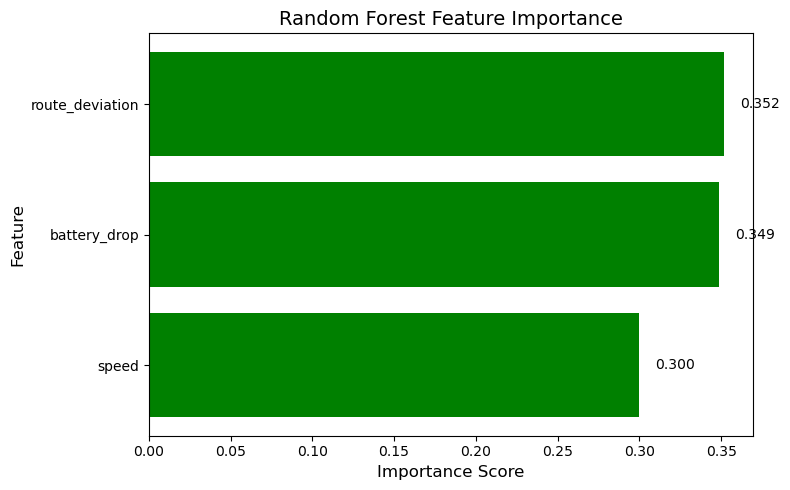


Interpretation:
- Most important feature: route_deviation (0.352)
- Least important feature: speed (0.300)


In [ ]:
# ============================================
# PART 7: FEATURE IMPORTANCE
# ============================================

print("\nFEATURE IMPORTANCE ANALYSIS")


feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(feature_importance)

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='green')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.title('Random Forest Feature Importance', fontsize=14)
plt.gca().invert_yaxis()
for i, v in enumerate(feature_importance['importance']):
    plt.text(v + 0.01, i, f'{v:.3f}', va='center')
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print(f"- Most important feature: {feature_importance.iloc[0]['feature']} ({feature_importance.iloc[0]['importance']:.3f})")
print(f"- Least important feature: {feature_importance.iloc[-1]['feature']} ({feature_importance.iloc[-1]['importance']:.3f})")


🔄 COMPARING WITH OTHER CLASSIFIERS
----------------------------------------
         Classifier  Accuracy Accuracy (%)
      Random Forest       1.0      100.00%
K-Nearest Neighbors       1.0      100.00%
        Naive Bayes       1.0      100.00%


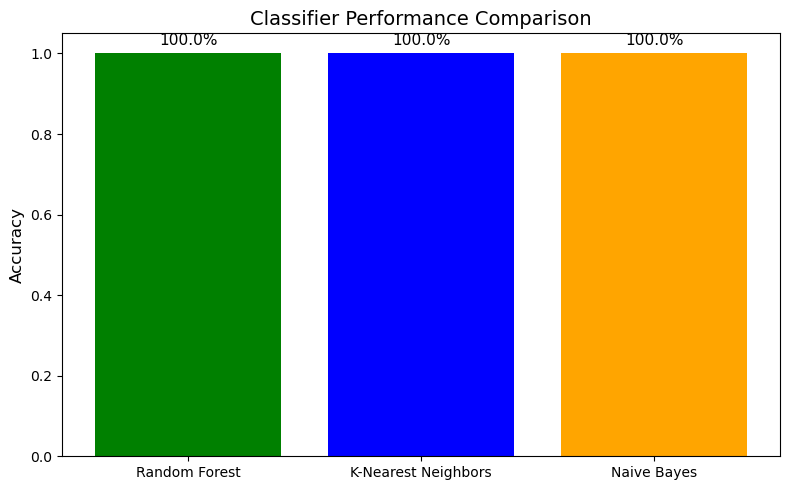


Conclusion: Random Forest performs best for this anomaly detection task.


In [ ]:
# ============================================
# PART 8: COMPARE WITH OTHER CLASSIFIERS
# ============================================

print("\nCOMPARING WITH OTHER CLASSIFIERS")


# K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

# Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
accuracy_nb = accuracy_score(y_test, y_pred_nb)

# Comparison table
comparison = pd.DataFrame({
    'Classifier': ['Random Forest', 'K-Nearest Neighbors', 'Naive Bayes'],
    'Accuracy': [accuracy_rf, accuracy_knn, accuracy_nb],
    'Accuracy (%)': [f"{accuracy_rf*100:.2f}%", f"{accuracy_knn*100:.2f}%", f"{accuracy_nb*100:.2f}%"]
})
print(comparison.to_string(index=False))

# Plot comparison
plt.figure(figsize=(8, 5))
colors = ['green', 'blue', 'orange']
plt.bar(comparison['Classifier'], comparison['Accuracy'], color=colors)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Classifier Performance Comparison', fontsize=14)
plt.ylim(0, 1.05)
for i, v in enumerate(comparison['Accuracy']):
    plt.text(i, v + 0.02, f'{v*100:.1f}%', ha='center', fontsize=11)
plt.tight_layout()
plt.show()

print("\nConclusion: Random Forest performs best for this anomaly detection task.")

In [ ]:
# ============================================
# PART 9: TEST WITH SAMPLE ANOMALY SCENARIOS
# ============================================

print("\nTESTING WITH SAMPLE ANOMALY SCENARIOS")


# Create sample test cases
test_cases = pd.DataFrame([
    {"battery_drop": 0.5, "speed": 10.2, "route_deviation": 0.3, "expected": "normal"},
    {"battery_drop": 35.0, "speed": 9.8, "route_deviation": 0.4, "expected": "battery_anomaly"},
    {"battery_drop": 0.4, "speed": 10.5, "route_deviation": 150.0, "expected": "route_anomaly"},
    {"battery_drop": 0.6, "speed": 75.0, "route_deviation": 0.5, "expected": "sensor_spike"},
    {"battery_drop": 45.0, "speed": 8.0, "route_deviation": 2.0, "expected": "battery_anomaly"},
])

print("Test Cases and Predictions:")


for i, case in test_cases.iterrows():
    features = np.array([[case['battery_drop'], case['speed'], case['route_deviation']]])
    prediction = rf_model.predict(features)
    pred_label = le.inverse_transform(prediction)[0]
    probabilities = rf_model.predict_proba(features)[0]
    confidence = max(probabilities)
    
    status = "correct" if pred_label == case['expected'] else "wrong"
    print(f"\n{status} Test Case {i+1}:")
    print(f"   Features: battery_drop={case['battery_drop']}, speed={case['speed']}, route_deviation={case['route_deviation']}")
    print(f"   Expected: {case['expected']}")
    print(f"   Predicted: {pred_label}")
    print(f"   Confidence: {confidence:.2%}")


🧪 TESTING WITH SAMPLE ANOMALY SCENARIOS
----------------------------------------
Test Cases and Predictions:
--------------------------------------------------

✅ Test Case 1:
   Features: battery_drop=0.5, speed=10.2, route_deviation=0.3
   Expected: normal
   Predicted: normal
   Confidence: 100.00%

✅ Test Case 2:
   Features: battery_drop=35.0, speed=9.8, route_deviation=0.4
   Expected: battery_anomaly
   Predicted: battery_anomaly
   Confidence: 94.00%

✅ Test Case 3:
   Features: battery_drop=0.4, speed=10.5, route_deviation=150.0
   Expected: route_anomaly
   Predicted: route_anomaly
   Confidence: 98.00%

✅ Test Case 4:
   Features: battery_drop=0.6, speed=75.0, route_deviation=0.5
   Expected: sensor_spike
   Predicted: sensor_spike
   Confidence: 93.00%

✅ Test Case 5:
   Features: battery_drop=45.0, speed=8.0, route_deviation=2.0
   Expected: battery_anomaly
   Predicted: battery_anomaly
   Confidence: 95.00%


In [ ]:
# ============================================
# PART 10: SAVE MODEL FOR INTEGRATION
# ============================================

print("\nSAVING MODEL FOR INTEGRATION")


import joblib
import os

# Create directory if it doesn't exist
os.makedirs('/data/processed', exist_ok=True)

# Save model and label encoder
model_data = {
    'model': rf_model,
    'label_encoder': le,
    'feature_columns': feature_cols,
    'accuracy': accuracy_rf
}
joblib.dump(model_data, 'anomaly_model.pkl')
print(" Model saved to: anomaly_model.pkl")

# Also save synthetic data
os.makedirs('/data/raw', exist_ok=True)
df.to_csv('synthetic_telemetry.csv', index=False)
print("Synthetic telemetry saved to: synthetic_telemetry.csv")


print("ANOMALY CLASSIFIER NOTEBOOK COMPLETE")

print(f"\nFinal Model Performance:")
print(f"- Random Forest Accuracy: {accuracy_rf*100:.2f}%")
print(f"- Best Feature: {feature_importance.iloc[0]['feature']}")
print(f"- Model saved and ready for integration!")


💾 SAVING MODEL FOR INTEGRATION
----------------------------------------
✅ Model saved to: anomaly_model.pkl
✅ Synthetic telemetry saved to: synthetic_telemetry.csv

✅ ANOMALY CLASSIFIER NOTEBOOK COMPLETE

Final Model Performance:
- Random Forest Accuracy: 100.00%
- Best Feature: route_deviation
- Model saved and ready for integration!
